# B4 · CBR uplift estimator and E3 (live session)

PLAN §7 B4 and §9 E3; drift item 8: **CBR is the uplift estimator**, the T-learner is the E3 baseline. Stream B owns it.

A **case** is one row of the intervention log: a member (problem), the offer they got or nothing (solution) and whether
they stayed (outcome). For a member and an offer, CBR **retrieves** the nearest past cases, **reuses** them as a small
A/B test (stay rate of neighbours who got the offer minus stay rate of neighbours who got nothing), and **revises** thin
evidence by shrinking it toward the offer's average. **Retain** (new outcomes become cases) comes with outcome logging.

**Fairness rules.** Only the intervention log is used to build and tune CBR. `true_uplift` is read once, to grade
(sections 7 and 11). A member never retrieves their own past case. Variants were fixed before any was graded.

The chosen estimator (V3) and `similar_cases` live in `anchorai.cbr.reasoner`; the planner uses them by default.

## 1. Load

**Look for:** 2,400 cases; 984 controls and about 350 per offer. The raw treated-minus-control gaps (+0.8 to +10.6 points)
are the offer averages CBR shrinks toward.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from anchorai.config import get_settings
from anchorai.discovery.scores import load_scores
from anchorai.discovery.uplift import t_learner
from anchorai.optimisation.model import load_tlearner_uplift
from anchorai.scenario.tables import generated_dir, read_tables
from scipy.stats import spearmanr
from sklearn.model_selection import KFold

SEED = get_settings().anchorai_seed
FIG, RES = Path("figures"), Path("results")
FIG.mkdir(exist_ok=True)
RES.mkdir(exist_ok=True)

tables = read_tables()
cases = tables["interventions"].assign(arm=lambda d: d["offer_id"].fillna("control"))
OFFERS = sorted(cases.loc[cases["treated"], "offer_id"].unique())
features = pd.read_parquet(generated_dir() / "features.parquet").set_index("member_id")
scores = load_scores().set_index("member_id").loc[features.index]

print(f"{len(cases)} cases for {len(features)} members, {features.shape[1]} features")
cases.groupby("arm").agg(cases=("stayed", "size"), stay_rate=("stayed", "mean")).round(
    3
)

2400 cases for 4000 members, 17 features


,cases,stay_rate
arm,,
checkin_message,354,0.678
class_pass,368,0.712
control,984,0.670
discount_1m,341,0.710
free_pt_session,353,0.776


## 2. What "similar" means: three candidate weightings

All 17 of A's features (the same inputs as the T-learner), standardised. Three ways to weight them, none designed from the
scenario's hidden formula: equal; by A's churn-model importance (mean absolute contribution among members' top drivers);
churn risk alone.

**Look for:** the importance weights: lifetime and visit change dominate; four features get 0.

In [2]:
scaled = (features - features.mean()) / features.std().replace(0, 1)

# A's churn model: mean absolute contribution of each feature among members' top-5 drivers.
drivers = pd.DataFrame(
    [dict(json.loads(d)) for d in scores["top_drivers"]], index=scores.index
)
importance = drivers.abs().fillna(0).mean().reindex(features.columns, fill_value=0.0)
importance *= len(importance) / importance.sum()
risk = scores["churn_prob"]

WEIGHTINGS = {
    "equal": scaled,
    "churn importance": scaled * np.sqrt(importance),
    "churn risk only": ((risk - risk.mean()) / risk.std()).to_frame(),
}
importance.sort_values(ascending=False).round(2).to_frame("weight").T

,lifetime,visit_change,age,avg_additional_charges_total,month_to_end_contract,trend_ratio,contract_period,avg_class_frequency_current_month,charges_per_month,avg_class_frequency_total,group_visits,contract_progress,promo_friends,near_location,gender,partner,phone
weight,5.71,3.81,2.26,1.56,1.52,0.57,0.57,0.48,0.2,0.16,0.1,0.03,0.02,0.0,0.0,0.0,0.0


## 3. Retrieve and reuse

For each offer, **one** neighbourhood: the k nearest cases among that offer's cases and the controls. Treated and control
neighbours are then equally close. (A first version took k nearest from each group separately; the null test in section 9
caught that it measured churn risk rather than offer effect.) Closer cases weigh more (a Gaussian kernel scaled to each
member's median neighbour distance). `noise` is the sampling variance of the local estimate.

The estimator lives in `anchorai.cbr.reasoner` (the app uses the same code); this notebook calls it with
each candidate feature weighting.

**Look for:** about 50 treated and 150 control neighbours per member and offer; local estimates for two members.

In [3]:
from anchorai.cbr.reasoner import CaseBase, estimate_uplift, nearest, similar_cases


def local_uplift(x, case_base, query_ids, k, kernel=True):
    """Retrieve + reuse with the package's estimator, on any feature weighting."""
    est = estimate_uplift(CaseBase(case_base, x), query_ids, k, kernel)
    return est[["member_id", "offer_id", "local", "noise", "n_treated", "n_control"]]


local_uplift(WEIGHTINGS["equal"], cases, np.array(["M0001", "M0008"]), k=200).round(3)

,member_id,offer_id,local,noise,n_treated,n_control
0,M0001,checkin_message,0.006,0.007,52,148
1,M0008,checkin_message,-0.061,0.006,59,141
2,M0001,class_pass,0.089,0.006,64,136
3,M0008,class_pass,0.095,0.006,65,135
4,M0001,discount_1m,0.087,0.007,47,153
5,M0008,discount_1m,0.086,0.007,56,144
6,M0001,free_pt_session,0.132,0.006,49,151
7,M0008,free_pt_session,0.277,0.006,48,152


## 4. Revise: empirical-Bayes shrinkage

`(n·local + m·average) / (n + m)` with n and m read from the data: weight on the local estimate = true spread between
members ÷ (spread + noise). Qini cannot choose m: with one m per offer the ranking inside an offer does not change.

**Look for:** `weight` 0 for check-in and class pass: the data show no difference between members beyond noise, so CBR
falls back to the offer average. Some weight on the local estimate for discount and PT.

In [4]:
def cbr_uplift(x, case_base, query_ids, k=200, kernel=True):
    """Retrieve + reuse + revise (anchorai.cbr.estimate_uplift) on any feature weighting."""
    return estimate_uplift(CaseBase(case_base, x), query_ids, k, kernel)


cbr_uplift(WEIGHTINGS["equal"], cases, features.index.to_numpy()).groupby("offer_id")[
    ["local", "prior", "weight", "uplift", "n_treated", "n_control"]
].mean().round(3)

,local,prior,weight,uplift,n_treated,n_control
offer_id,,,,,,
checkin_message,0.011,0.008,0.000,0.008,52.469,147.531
class_pass,0.046,0.042,0.000,0.042,54.937,145.063
discount_1m,0.034,0.040,0.332,0.037,52.895,147.105
free_pt_session,0.098,0.106,0.500,0.099,53.842,146.158


## 5. Can the history choose the settings?

The **Qini** score on the intervention log: rank cases by predicted uplift and check whether the top shows a bigger
treated-vs-control gap. Out-of-fold (5-fold CV), so no case is scored by a model that saw it. Ties are broken at random.

**Look for:** the reference points. Random ≈ 0 and a constant score ≈ 0.006 show the noise level; only churn risk scores
clearly above it. Every weighting and k sits inside the noise: the history cannot pick a setting.

In [5]:
SEEDS = range(10)


def qini(score, treated, stayed):
    """Area between the Qini curve and the random line, per treated case (0 = no better than random)."""
    # Ties (e.g. every member shrunk to the same average) are broken at random, so they score as random.
    order = np.lexsort((np.random.default_rng(0).random(len(score)), -score))
    t, y = treated[order], stayed[order].astype(float)
    n_t, n_c = np.cumsum(t), np.cumsum(~t)
    gain = np.cumsum(y * t) - np.cumsum(y * ~t) * np.divide(
        n_t, n_c, out=np.zeros(len(t)), where=n_c > 0
    )
    return (gain - gain[-1] * np.arange(1, len(t) + 1) / len(t)).mean() / t.sum()


def history_qini(estimates: pd.Series) -> float:
    """Mean per-offer Qini on the intervention log: does a high estimate mean a bigger treated-vs-control gap?"""
    values = []
    for o in OFFERS:
        sub = cases[cases["arm"].isin([o, "control"])]
        score = estimates.reindex(
            pd.MultiIndex.from_arrays([sub["member_id"], [o] * len(sub)])
        ).fillna(0)
        values.append(
            qini(score.to_numpy(), sub["treated"].to_numpy(), sub["stayed"].to_numpy())
        )
    return float(np.mean(values))


def out_of_fold(estimator, seed):
    """Score every case with a model built only from the other folds' cases."""
    parts = [
        estimator(cases.iloc[tr], cases.iloc[te]["member_id"].to_numpy())
        for tr, te in KFold(5, shuffle=True, random_state=seed).split(cases)
    ]
    return pd.concat(parts).set_index(["member_id", "offer_id"])["uplift"]


keys = tables["true_uplift"].set_index(["member_id", "offer_id"]).index
references = {
    "risk as uplift": pd.Series(
        risk.reindex(keys.get_level_values(0)).to_numpy(), index=keys
    ),
    "constant": pd.Series(0.0, index=keys),
    "random (mean of 10)": None,
}
ref = {name: history_qini(s) for name, s in references.items() if s is not None}
ref["random (mean of 10)"] = np.mean(
    [
        history_qini(pd.Series(np.random.default_rng(s).random(len(keys)), index=keys))
        for s in SEEDS
    ]
)

rows = []
for name, wx in WEIGHTINGS.items():
    for k in [50, 100, 200, 400]:
        for seed in range(5):
            est = out_of_fold(
                lambda base, ids, wx=wx, k=k: local_uplift(
                    wx, base, ids, k, kernel=False
                ).rename(columns={"local": "uplift"}),
                seed,
            )
            rows.append({"weighting": name, "k": k, "qini": history_qini(est)})
tuning = (
    pd.DataFrame(rows).groupby(["weighting", "k"])["qini"].agg(["mean", "std"]).round(4)
)
tuning.to_csv(RES / "b4_cbr_tuning.csv")
print("reference points:", {k: round(v, 4) for k, v in ref.items()})
tuning.unstack("k")

reference points: {'risk as uplift': 0.0148, 'constant': 0.0056, 'random (mean of 10)': np.float64(-0.0003)}


mean                             std                  \
k                    50      100     200     400     50      100     200   
weighting                                                                  
churn importance  0.0018 -0.0042  0.0014  0.0013  0.0031  0.0028  0.0030   
churn risk only  -0.0046 -0.0015  0.0002 -0.0021  0.0022  0.0022  0.0025   
equal            -0.0033 -0.0047 -0.0026  0.0030  0.0026  0.0029  0.0027   

                          
k                    400  
weighting                 
churn importance  0.0037  
churn risk only   0.0027  
equal             0.0029

## 6. Three improvements, fixed before grading

Each borrows strength where neighbourhoods are thin: **V1** pooled responsiveness (any offer vs control among the nearest
of all cases, added to each offer's average); **V2** shrink toward the member's segment × offer average; **V3** distance
weighting. V0 is the plain version. Chosen by history Qini over 10 seeds; only the winner is graded against the truth.

**Look for:** all four inside the noise (±0.004). V3 is chosen by the rule, not by a meaningful margin.

In [6]:
K_OFFER, K_ALL = (
    200,
    360,
)  # the same 15% share of each pool, fixed before looking at any result
X = WEIGHTINGS["equal"]


def offer_priors(base):
    rate = base.groupby("arm")["stayed"].mean()
    return rate.drop("control") - rate["control"]


def eb(local, noise, prior):
    """Empirical-Bayes shrinkage of noisy local estimates toward a prior."""
    spread = max(np.nanvar(local - prior) - np.nanmean(noise), 0.0)
    w = np.nan_to_num(spread / (spread + noise))
    return w * np.nan_to_num(local) + (1 - w) * prior


def v1(base, ids):
    """Pooled responsiveness: any-offer treated minus control among the nearest of all cases."""
    _, idx, keep = nearest(CaseBase(base, X), base, ids, K_ALL)
    t, y = base["treated"].to_numpy()[idx], base["stayed"].to_numpy(float)[idx]
    p_t, p_c = (
        (y * t * keep).sum(1) / (t * keep).sum(1),
        (y * ~t * keep).sum(1) / (~t * keep).sum(1),
    )
    noise = p_t * (1 - p_t) / (t * keep).sum(1) + p_c * (1 - p_c) / (~t * keep).sum(1)
    overall = (
        base.loc[base["treated"], "stayed"].mean()
        - base.loc[~base["treated"], "stayed"].mean()
    )
    deviation = eb(p_t - p_c, noise, overall) - overall
    return pd.concat(
        [
            pd.DataFrame({"member_id": ids, "offer_id": o, "uplift": p + deviation})
            for o, p in offer_priors(base).items()
        ],
        ignore_index=True,
    )


def v2(base, ids):
    """Shrink toward the member's segment x offer average, itself shrunk toward the offer average."""
    segment = scores["segment_id"]
    seg = segment.reindex(base["member_id"]).to_numpy()
    est = local_uplift(X, base, ids, K_OFFER, kernel=False)
    frames = []
    for o, offer_prior in offer_priors(base).items():
        gaps, noise = {}, {}
        for s in np.unique(seg):
            t = base["stayed"][((base["arm"] == o).to_numpy()) & (seg == s)]
            c = base["stayed"][((base["arm"] == "control").to_numpy()) & (seg == s)]
            gaps[s], noise[s] = t.mean() - c.mean(), t.var() / len(t) + c.var() / len(c)
        seg_prior = pd.Series(
            eb(
                np.array(list(gaps.values())),
                np.array(list(noise.values())),
                offer_prior,
            ),
            index=list(gaps),
        )
        e = est[est["offer_id"] == o]
        prior = seg_prior.reindex(segment.reindex(e["member_id"])).to_numpy()
        frames.append(
            e.assign(uplift=eb(e["local"].to_numpy(), e["noise"].to_numpy(), prior))
        )
    return pd.concat(frames, ignore_index=True)


VARIANTS = {
    "V0 current": lambda base, ids: cbr_uplift(X, base, ids, K_OFFER, kernel=False),
    "V1 pooled responsiveness": v1,
    "V2 segment prior": v2,
    "V3 distance weighting": lambda base, ids: cbr_uplift(
        X, base, ids, K_OFFER, kernel=True
    ),
}
variants = (
    pd.DataFrame(
        [
            {"variant": n, "seed": s, "qini": history_qini(out_of_fold(f, s))}
            for n, f in VARIANTS.items()
            for s in SEEDS
        ]
    )
    .groupby("variant")["qini"]
    .agg(["mean", "std"])
    .round(4)
)
variants.to_csv(RES / "b4_cbr_variants.csv")
WINNER = variants["mean"].idxmax()
print("chosen on history:", WINNER)
variants

chosen on history: V3 distance weighting


,mean,std
variant,,
V0 current,-0.0070,0.0034
V1 pooled responsiveness,-0.0071,0.0045
V2 segment prior,-0.0090,0.0037
V3 distance weighting,-0.0055,0.0030


## 7. E3 against the truth (graded once)

Rank correlation with `true_uplift` per offer and over all member × offer pairs, and the mean true uplift of each method's
top picks (top 10% of pairs; top 2.5% of members per offer).

**Look for:** CBR level with the T-learner over all pairs, better for discount and PT, and no ranking for check-in and
class pass (NaN: every member gets the average). Risk ranks well inside an offer because the scenario's effects grow with
risk; it cannot tell offers apart.

In [7]:
truth = tables["true_uplift"].set_index(["member_id", "offer_id"])["uplift"]
cbr = VARIANTS[WINNER](cases, features.index.to_numpy())
methods = {
    "CBR": cbr.set_index(["member_id", "offer_id"])["uplift"].reindex(keys),
    "T-learner": load_tlearner_uplift().reindex(keys),
    "risk as uplift": references["risk as uplift"],
    "random": pd.Series(np.random.default_rng(SEED).random(len(keys)), index=keys),
}


def top10_true_uplift(est):
    """Mean true uplift of the members a method ranks in its top 10% for each offer."""
    return {
        o: truth.loc[
            est.xs(o, level="offer_id", drop_level=False).nlargest(len(est) // 40).index
        ].mean()
        for o in OFFERS
    }


rows = []
for name, est in methods.items():
    top = top10_true_uplift(est)
    for o in OFFERS:
        sel = keys.get_level_values("offer_id") == o
        rows.append(
            {
                "method": name,
                "offer": o,
                "spearman": spearmanr(est[sel], truth[sel]).statistic,
                "top10_true_uplift": top[o],
            }
        )
    rows.append(
        {
            "method": name,
            "offer": "all pairs",
            "spearman": spearmanr(est, truth).statistic,
            "top10_true_uplift": truth.loc[est.nlargest(len(est) // 10).index].mean(),
        }
    )
e3_truth = pd.DataFrame(rows)
e3_truth.round(4).to_csv(RES / "e3_uplift_vs_truth.csv", index=False)
print("mean true uplift:", truth.groupby(level="offer_id").mean().round(3).to_dict())
display(e3_truth.pivot(index="method", columns="offer", values="spearman").round(3))
e3_truth.pivot(index="method", columns="offer", values="top10_true_uplift").round(3)

mean true uplift: {'checkin_message': 0.029, 'class_pass': 0.054, 'discount_1m': 0.031, 'free_pt_session': 0.116}


/tmp/ipykernel_819194/782625902.py:30: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  "spearman": spearmanr(est[sel], truth[sel]).statistic,


offer,all pairs,checkin_message,class_pass,discount_1m,free_pt_session
method,,,,,
CBR,0.393,NaN,NaN,0.479,0.639
T-learner,0.392,0.264,0.337,0.273,0.608
random,-0.005,0.004,0.019,-0.016,-0.016
risk as uplift,0.417,0.832,0.067,0.684,0.866


offer,all pairs,checkin_message,class_pass,discount_1m,free_pt_session
method,,,,,
CBR,0.177,0.029,0.054,0.105,0.248
T-learner,0.159,0.058,0.084,0.086,0.233
random,0.056,0.029,0.052,0.028,0.113
risk as uplift,0.125,0.078,0.052,0.109,0.261


## 8. E3 on the history (out-of-fold Qini)

The T-learner is retrained inside each fold with A's own `t_learner`, so it is scored fairly too.

**Look for:** neither CBR nor the T-learner beats random on the history; only risk does.

In [8]:
history = []
for seed in range(5):
    history += [
        {"method": "CBR", "qini": history_qini(out_of_fold(VARIANTS[WINNER], seed))},
        {
            "method": "T-learner",
            "qini": history_qini(
                out_of_fold(
                    lambda base, ids: t_learner(
                        features, base.drop(columns="arm"), OFFERS, SEED
                    ).query("member_id in @ids"),
                    seed,
                )
            ),
        },
        {"method": "risk as uplift", "qini": ref["risk as uplift"]},
        {
            "method": "random",
            "qini": history_qini(
                pd.Series(np.random.default_rng(seed).random(len(keys)), index=keys)
            ),
        },
    ]
e3_history = (
    pd.DataFrame(history).groupby("method")["qini"].agg(["mean", "std"]).round(4)
)
e3_history.to_csv(RES / "e3_history_qini.csv")
e3_history

,mean,std
method,,
CBR,-0.0061,0.0040
T-learner,-0.0049,0.0029
random,0.0024,0.0068
risk as uplift,0.0148,0.0000


## 9. Null test

Shuffle who got which offer: effects are then zero by construction, and CBR should find nothing.

**Look for:** weight on the local estimates near 0 (CBR falls back to averages) and mean estimates near 0. The rank
correlation swings (about ±0.3) because nearly all estimates are tied; report it as a caveat.

In [9]:
null_rows = []
for seed in range(5):
    shuffled = np.random.default_rng(seed).permutation(len(cases))
    null_cases = cases.assign(
        **{c: cases[c].to_numpy()[shuffled] for c in ["arm", "offer_id", "treated"]}
    )
    est = VARIANTS[WINNER](null_cases, features.index.to_numpy())
    null_rows.append(
        {
            "seed": seed,
            "mean_estimate": est["uplift"].mean(),
            "mean_weight_on_local": est["weight"].mean(),
            "spearman_with_truth": spearmanr(
                est.set_index(["member_id", "offer_id"])["uplift"].reindex(keys), truth
            ).statistic,
        }
    )
e3_null = pd.DataFrame(null_rows)
e3_null.round(4).to_csv(RES / "e3_null_test.csv", index=False)
print(
    f"real data: mean estimate {cbr['uplift'].mean():.3f}, mean weight on local {cbr['weight'].mean():.3f}"
)
e3_null.round(3)

real data: mean estimate 0.047, mean weight on local 0.208


,seed,mean_estimate,mean_weight_on_local,spearman_with_truth
0,0,0.004,0.000,0.129
1,1,0.028,0.000,-0.319
2,2,-0.019,0.000,-0.295
3,3,-0.014,0.083,0.107
4,4,-0.010,0.015,-0.334


## 10. Similar cases: the explanation

The neighbours behind one estimate, the precedents staff will see ("3 of 4 similar members who got a PT session stayed").

**Look for:** a mix of treated and control neighbours, nearest first, each with its outcome.

In [10]:
example = cbr.query("offer_id == 'free_pt_session'").nlargest(1, "uplift").iloc[0]
print(
    f"{example['member_id']}: free PT {example['uplift']:+.3f} (local {example['local']:+.3f}, "
    f"{example['n_treated']:.0f} treated / {example['n_control']:.0f} control neighbours, weight {example['weight']:.2f})"
)
pd.DataFrame(similar_cases(CaseBase(cases, X), example["member_id"], "free_pt_session"))

M3911: free PT +0.236 (local +0.391, 49 treated / 151 control neighbours, weight 0.45)


,member_id,offer_id,week_start,stayed,distance
0,M0661,free_pt_session,2026-08-03,True,2.031
1,M1069,free_pt_session,2026-07-27,False,2.179
2,M3180,free_pt_session,2026-08-24,True,2.404
3,M0262,NaN,2026-08-10,False,2.474
4,M0702,NaN,2026-07-27,True,2.537
5,M2783,NaN,2026-07-27,True,2.586
6,M3273,NaN,2026-08-17,False,2.587
7,M3483,NaN,2026-10-05,False,2.790
8,M2704,free_pt_session,2026-08-10,True,2.906
9,M3433,NaN,2026-08-10,False,3.023


## 11. Do better estimates mean better plans?

The greedy planner from `b_plan_model` on CBR and on T-learner estimates, graded by the evaluator.

**Look for:** at today's 36 staff hours CBR plans keep about 30% fewer members: when staff time binds the planner lives on
check-ins, and CBR cannot say which members a check-in helps. With more staff they are level.

In [11]:
from anchorai.db.session import get_engine
from anchorai.optimisation.baselines import greedy_uplift
from anchorai.optimisation.evaluate import evaluate, load_truth
from anchorai.optimisation.model import load_instance
from sqlmodel import Session

grade, session = load_truth(), Session(get_engine())
plans = []
for name in ["CBR", "T-learner"]:
    instance = load_instance(session, uplift=methods[name])
    for hours, budget in [(36, 1500), (72, 1500), (120, 4000)]:
        plan = greedy_uplift(instance.options, instance.limits(budget, hours * 60))
        plans.append(
            {
                "uplift": name,
                "staff_hours": hours,
                "budget": budget,
                **evaluate(plan, grade),
            }
        )
plan_quality = pd.DataFrame(plans)
plan_quality.round(2).to_csv(RES / "e3_plan_quality.csv", index=False)
plan_quality.pivot(
    index=["staff_hours", "budget"], columns="uplift", values="extra_retained"
).round(1)

,uplift,CBR,T-learner
staff_hours,budget,,
36,1500,19.4,27.9
72,1500,42.5,43.6
120,4000,60.7,60.0


## 12. Figure

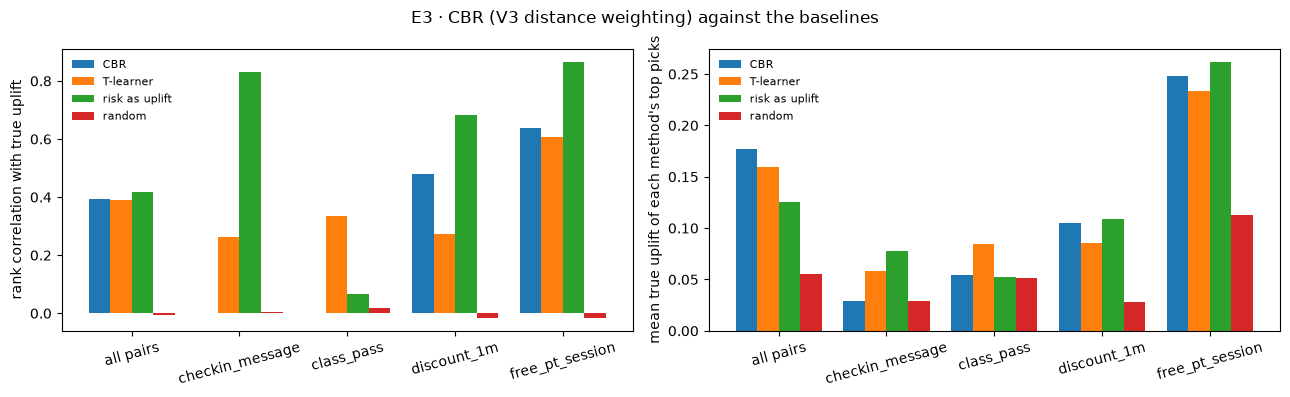

In [12]:
order = ["CBR", "T-learner", "risk as uplift", "random"]
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, metric, label in [
    (axes[0], "spearman", "rank correlation with true uplift"),
    (axes[1], "top10_true_uplift", "mean true uplift of each method's top picks"),
]:
    e3_truth.pivot(index="offer", columns="method", values=metric)[order].plot.bar(
        ax=ax, rot=15, width=0.8
    )
    ax.set_ylabel(label)
    ax.set_xlabel("")
    ax.legend(frameon=False, fontsize=8)
fig.suptitle(f"E3 · CBR ({WINNER}) against the baselines")
fig.tight_layout()
fig.savefig(FIG / "e3_uplift.png")
plt.show()

## Findings (2026-10-19)

1. **CBR ties the T-learner overall** (rank correlation 0.39 vs 0.39 over all member × offer pairs) and beats it for PT
   (0.64 vs 0.61) and the discount (0.48 vs 0.27).
2. **It cannot tell members apart for check-in and class pass.** On 2,400 randomised cases with effects of a few points,
   shrinkage finds no spread beyond noise and returns the offer average.
3. **The history cannot tune CBR.** Every weighting, k and variant sits inside the Qini noise; only churn risk shows a
   clear signal. Settings are therefore fixed by rule (equal weights, k = 200, V3 by the pre-registered rule).
4. **Plans:** at the seeded 36 staff hours, plans on CBR estimates keep 19.4 extra members against 27.9 on the T-learner;
   at 72 and 120 hours they are level. **Flagged for a team decision** (HANDOFFS): keep CBR as the estimator per PLAN
   drift item 8, or let the T-learner supply the numbers and CBR the explanations.
5. **Null test:** with offers shuffled CBR falls back to averages (weight on local ≈ 0); the rank correlation with the
   truth is unstable (±0.3) because estimates are tied.
6. A first CBR version (separate neighbourhoods per group) looked much better (0.54); the null test showed it was
   measuring churn risk. Those numbers must not be reported.